# Synthetic Dataset Generator

This notebook generates synthetic sedimentary time series based on Milankovitch cycles, incorporating variations in sedimentation rates, orbital component combinations, and noise conditions.

The resulting dataset is used for training and evaluating the deep learning models presented in the accompanying manuscript.

## 1. Libraries and Dependencies

In [7]:
# Import required libraries
import json
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

## 2. Dataset Configuration

In [ ]:

# Target orbital periods (kyr)
PERIODS = {"precession": 21, "obliquity": 41, "E1": 100, "E2": 405}
ALL_CYCLES = ["precession", "obliquity", "E1", "E2"]

# Dataset configuration
DT = 1.0
T_MAX_MA = 50
LENGTH_RANGE = (2500.0, 5000.0)
LENGTH_MAX = LENGTH_RANGE[1]
N_POINTS_DEPTH = 2000

# Temporal splitting with buffers to prevent overlap between subsets
SPLIT_FRACS = {"train": 0.70, "val": 0.15, "test": 0.15}

t0_max = T_MAX_MA * 1000 - LENGTH_MAX
usable_span = t0_max - 2 * LENGTH_MAX

SPLIT_T0_RANGES = {}
_t = 0.0
for name, frac in SPLIT_FRACS.items():
    width = usable_span * frac
    SPLIT_T0_RANGES[name] = (_t, _t + width)
    _t += width + LENGTH_MAX

# Input and output paths
DATA_DIR = Path("astronomical_solutions")
PATH_E1 = DATA_DIR / "long_eccentricity.txt" # Astronomical solution by Zeebe and Louren (2019), Zeebe and Lourens (2019-08-14), Zeebe and Lourens (2022), and Kocken and Zeebe (2023).
PATH_E2 = DATA_DIR / "short_eccentricity.txt"
PATH_ORBITAL = DATA_DIR / "obliquity_precession.txt"

OUTPUT_DIR = Path("synthetic_dataset")
OUTPUT_DIR.mkdir(exist_ok=True)

print("t0 range per split (kyr):")
for name, (a, b) in SPLIT_T0_RANGES.items():
    print(f"  {name:5s}: [{a:8.0f}, {b:8.0f}] -> series end at up to {b + LENGTH_MAX:8.0f}")

# Plot settings
mpl.rcParams.update({
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.5,
    "grid.alpha": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#999999", "axes.linewidth": 0.7,
})

t0 range per split (kyr):
  train: [       0,    24500] -> series end at up to    29500
  val  : [   29500,    34750] -> series end at up to    39750
  test : [   39750,    45000] -> series end at up to    50000


## References
- Kocken, I., & Zeebe, R. E. (2023). *snvecR: Calculate Earth's Obliquity and Precession in the Past*. Zenodo. https://doi.org/10.5281/zenodo.7865279

- Zeebe, R. E., & Lourens, L. J. (2019). Solar System chaos and the Paleocene–Eocene boundary age constrained by geology and astronomy. *Science*, 365, 926–929. https://doi.org/10.1126/science.aax0612

- Zeebe, R.E.; Lourens, L.J. (2019-08-14): NOAA/WDS Paleoclimatology - Astronomical Solution ZB18a 0-100 Ma for Earth's Orbital Eccentricity and Inclination. [indicate subset used]. NOAA National Centers for Environmental Information. https://doi.org/10.25921/gtcb-e158. Accessed Jun 2026.

- Zeebe, R. E., & Lourens, L. J. (2022). A deep-time dating tool for paleo-applications utilizing obliquity and precession cycles: The role of dynamical ellipticity and tidal dissipation. *Paleoceanography and Paleoclimatology*, 37, e2021PA004349. https://doi.org/10.1029/2021PA004349

## 3. Astronomical Data Loading

In [9]:
def load_astronomical_txt(path, column_names, skiprows=0, sep=r"\s+", lineterminator=None):
    """Load astronomical data, converting ages to positive values and sorting by time (0–50 Ma)."""
    df = pd.read_csv(path, sep=sep, skiprows=skiprows, header=None,
                     names=column_names, lineterminator=lineterminator)
    df["time_ka"] = df["time_ka"].abs()
    df = df[df["time_ka"] <= T_MAX_MA * 1000]
    return df.sort_values("time_ka").reset_index(drop=True)


# Load eccentricity components
E1_raw = load_astronomical_txt(PATH_E1, ["time_ka", "E1"])
E2_raw = load_astronomical_txt(PATH_E2, ["time_ka", "E2"])

# Load obliquity and precession (CSV with CR line endings)
orbital_raw = load_astronomical_txt(
    PATH_ORBITAL, ["time_ka", "obliquity", "precession"],
    skiprows=1, sep=",", lineterminator="\r"
)

# Check time ranges and sampling intervals
for name, df in [("E1", E1_raw), ("E2", E2_raw), ("obliquity/precession", orbital_raw)]:
    step = np.diff(df["time_ka"].to_numpy())
    print(f"{name:>20s}: {len(df):7d} rows | "
          f"{df['time_ka'].min():6.0f}-{df['time_ka'].max():6.0f} ka | "
          f"step {step.min():.2f}-{step.max():.2f} ka")

                  E1:   31251 rows |      0- 50000 ka | step 1.60-1.60 ka
                  E2:   31251 rows |      0- 50000 ka | step 1.60-1.60 ka
obliquity/precession:  125001 rows |      0- 50000 ka | step 0.40-0.40 ka


## 4. Astronomical Data Resampling and Normalization

In [10]:
def resample_series(t_src, y_src, t_target):
    """Linear interpolation onto t_target. The target grid lies inside the
    overlap of the three source files, so no extrapolation is involved."""
    return np.interp(t_target, t_src, y_src)


def zscore(y):
    return (y - np.mean(y)) / np.std(y)


# Overlap of the three files, on a regular DT grid. The upper end is trimmed
# rather than rounded up, so the grid never runs past the source data.
t_min = max(E1_raw["time_ka"].min(), E2_raw["time_ka"].min(), orbital_raw["time_ka"].min())
t_max = min(E1_raw["time_ka"].max(), E2_raw["time_ka"].max(), orbital_raw["time_ka"].max())
t_common = np.arange(t_min, t_max + DT, DT)
t_common = t_common[t_common <= t_max]

# Each cycle is standardised over the whole solution, putting the four on a
# common scale before the per-sample amplitude weights are drawn. Within an
# individual window the standard deviations are not exactly 1, which is why
# generate_synthetic_series recomputes a reference std from the window itself.
cycles_common = {
    "precession": zscore(resample_series(orbital_raw["time_ka"], orbital_raw["precession"], t_common)),
    "obliquity":  zscore(resample_series(orbital_raw["time_ka"], orbital_raw["obliquity"], t_common)),
    "E1":         zscore(resample_series(E1_raw["time_ka"], E1_raw["E1"], t_common)),
    "E2":         zscore(resample_series(E2_raw["time_ka"], E2_raw["E2"], t_common)),
}

print(f"Common grid: {len(t_common)} points, "
      f"{t_common.min():.0f}-{t_common.max():.0f} ka, step {DT:.0f} ka")

Common grid: 50001 points, 0-50000 ka, step 1 ka


## 5. Visualization of the Astronomical Components

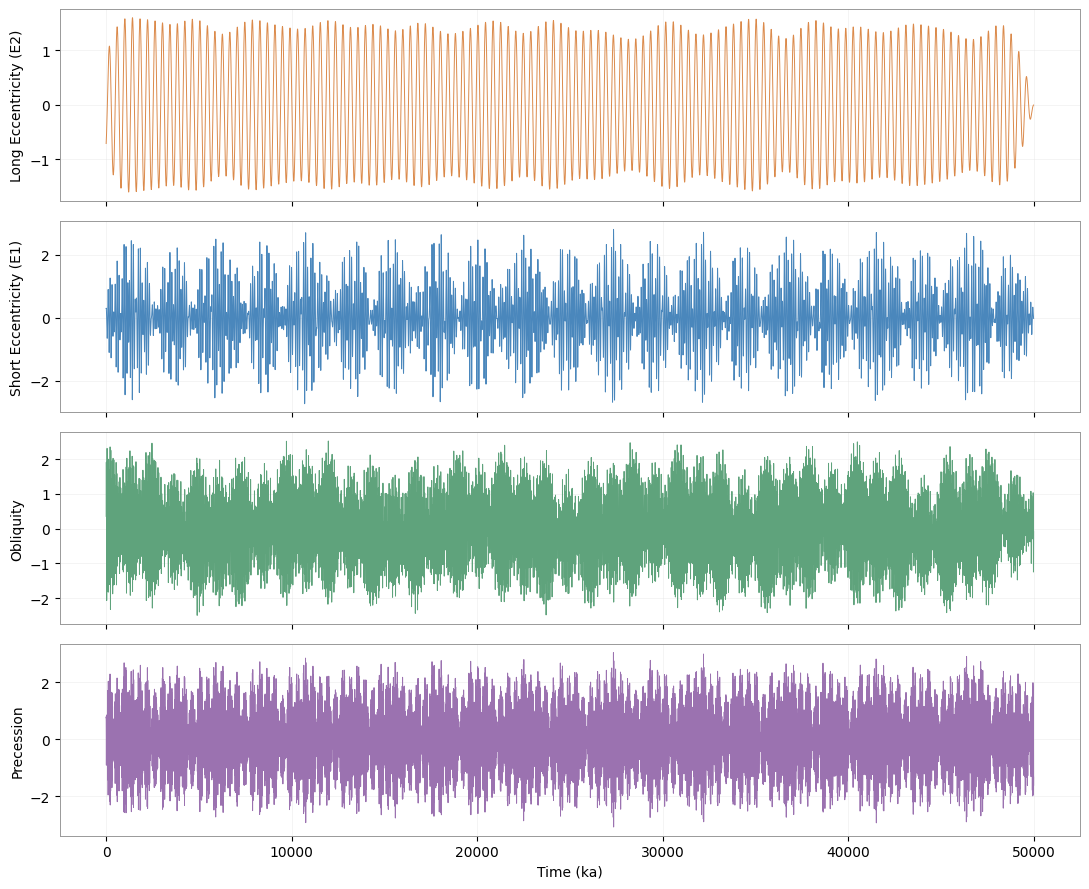

In [11]:
# Color palette and labels for the astronomical components.
COLORS = {"E2": "#DB8A4B", "E1": "#4A87BC", "obliquity": "#5FA37C", "precession": "#9B72B0"}
LABELS = {"E2": "Long Eccentricity (E2)", "E1": "Short Eccentricity (E1)",
          "obliquity": "Obliquity", "precession": "Precession"}

# Plot the astronomical components from the longest to the shortest period.
fig, axs = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, c in zip(axs, ["E2", "E1", "obliquity", "precession"]):
    ax.plot(t_common, cycles_common[c], lw=0.7, color=COLORS[c])
    ax.set_ylabel(LABELS[c])
axs[-1].set_xlabel("Time (ka)")
plt.tight_layout()

# Save the figure in vector and raster formats.
for ext in ("pdf", "png"):
    plt.savefig(f"figure_astronomical_solutions.{ext}", bbox_inches="tight", dpi=300)
plt.show()

## 6. Sedimentation Rate and Time-to-Depth Conversion

In [12]:
def sr_rate(t, params):
    """Calculate sedimentation rates (cm/kyr) for constant, trend, or step modes."""
    if params["mode"] == "trend":
        return np.linspace(params["sr_start"], params["sr_end"], len(t))
    if params["mode"] == "step":
        return np.where(t < params["t_switch"], params["sr_start"], params["sr_end"])
    return np.full_like(t, params["sr_start"])


def generate_sedimentation_profile(t, mode, rng, sr_range=(1, 10), factor_range=(1.5, 1.99)):
    """Generate a depth profile using constant, trend, or step sedimentation rates,
    with variations limited to approximately a factor of two."""
    if mode not in ("constant", "trend", "step"):
        raise ValueError(f"Unknown sedimentation rate mode: {mode}")

    if mode == "constant":
        sr_start = sr_end = float(rng.uniform(*sr_range))
    else:
        factor = rng.uniform(*factor_range)
        if rng.random() < 0.5:                      # rate increases downsection
            sr_start = float(rng.uniform(sr_range[0], sr_range[1] / factor))
            sr_end = sr_start * factor
        else:                                       # rate decreases
            sr_start = float(rng.uniform(sr_range[0] * factor, sr_range[1]))
            sr_end = sr_start / factor

    params = {"mode": mode, "sr_start": sr_start, "sr_end": float(sr_end)}
    if mode == "step":
        span = t.max() - t.min()
        params["t_switch"] = float(rng.uniform(t.min() + 0.2 * span,
                                               t.max() - 0.2 * span))

    return np.cumsum(sr_rate(t, params) * np.gradient(t)), params


def time_to_depth(y, z, n_points=N_POINTS_DEPTH):
    """Interpolate a time-domain series onto a uniformly spaced depth grid."""
    z_uniform = np.linspace(z.min(), z.max(), n_points)
    return z_uniform, np.interp(z_uniform, z, y)

## 7. Noise Generation and Contamination

In [13]:
# Noise levels: AR(1) coefficient (rho) and red/white noise scaling factors.
NOISE_LEVELS = {
    "n1": {"rho": 0.55, "k_red": 1.0, "k_white": 0.3},
    "n2": {"rho": 0.70, "k_red": 3.0, "k_white": 0.7},
    "n3": {"rho": 0.85, "k_red": 8.0, "k_white": 1.5},
}
NOISE_LEVEL_NAMES = list(NOISE_LEVELS)

# Combined noise scaling factor for SNR calculations.
K_TOTAL = {name: float(np.hypot(p["k_red"], p["k_white"]))
           for name, p in NOISE_LEVELS.items()}


def generate_ar1_noise(n, rho, rng):
    """Generate AR(1) red noise with autocorrelation coefficient rho."""
    eps = rng.normal(0, 1.0, size=n)
    x = np.empty(n)
    x[0] = eps[0]
    for i in range(1, n):
        x[i] = rho * x[i - 1] + eps[i]
    return x


def add_contamination(y, noise_level, ref_std, rng):
    """Add red and white noise scaled relative to the reference signal standard deviation."""
    level = NOISE_LEVELS[noise_level]
    red = generate_ar1_noise(len(y), level["rho"], rng)
    white = rng.normal(0, 1.0, size=len(y))
    red = red / np.std(red) * (level["k_red"] * ref_std)
    white = white / np.std(white) * (level["k_white"] * ref_std)
    return y + red + white

## 8. Synthetic Series Generation

In [14]:

def generate_synthetic_series(active_cycles, t0, length_kyr, rng,
                              noise_level=None, sr_mode="constant"):
    """Generate a synthetic series by combining orbital components, converting
    time to depth, and optionally adding noise.

    Returns the depth axis, synthetic series, amplitude weights, and
    sedimentation rate parameters.
    """
    mask = (t_common >= t0) & (t_common < t0 + length_kyr)
    t_window = t_common[mask] - t0

    amplitudes = {c: float(rng.uniform(0.2, 1.0)) for c in active_cycles}
    components = {c: amplitudes[c] * cycles_common[c][mask] for c in active_cycles}
    y_window = sum(components.values())

    # Scale noise using the mean standard deviation of individual components
    # to maintain comparable per-component SNR across orbital combinations.
    ref_std = float(np.mean([np.std(v) for v in components.values()]))

    z, sr_params = generate_sedimentation_profile(t_window, sr_mode, rng)
    z_uniform, y_depth = time_to_depth(y_window, z)

    if noise_level is not None:
        y_depth = add_contamination(y_depth, noise_level, ref_std, rng)

    return z_uniform, y_depth, amplitudes, sr_params

## 9. Dataset Composition and Sample Generation

In [15]:
# Selected combinations of orbital components.
COMBOS = [
    ("precession",), ("obliquity",), ("E1",), ("E2",),
    ("precession", "obliquity"),
    ("E1", "E2"),
    ("obliquity", "E2"),
    ("precession", "E1", "E2"),
    ("precession", "obliquity", "E1"),
]

# Assign twice the weight to multi-cycle combinations to balance label occurrence.
COMBO_WEIGHTS = {combo: (1 if len(combo) == 1 else 2) for combo in COMBOS}
TOTAL_WEIGHT = sum(COMBO_WEIGHTS.values())  # 4x1 + 5x2 = 14

SR_MODES = ["trend", "step"]
N_NEG = 3220   # Number of pure-noise samples.

# Define experimental groups based on noise and sedimentation rate variations.
# Group 0 is the unperturbed control; group 4 (pure noise) is generated separately.
N_UNIT_CONTROL = 200
N_UNIT_TREATMENT = 470

GROUP_SPEC = {
    "0": {"noise": False, "var_sr": False, "n_unit": N_UNIT_CONTROL},
    "1": {"noise": True,  "var_sr": False, "n_unit": N_UNIT_TREATMENT},
    "2": {"noise": False, "var_sr": True,  "n_unit": N_UNIT_TREATMENT},
    "3": {"noise": True,  "var_sr": True,  "n_unit": N_UNIT_TREATMENT},
}


def allocate_splits(n):
    """Assign samples to training, validation, and test subsets."""
    n_val = round(n * SPLIT_FRACS["val"])
    n_test = round(n * SPLIT_FRACS["test"])
    return ["train"] * (n - n_val - n_test) + ["val"] * n_val + ["test"] * n_test


def build_group(group_name, spec, rng):
    """Generate synthetic samples for a specified experimental group."""
    records = []

    for combo in COMBOS:
        n_combo = spec["n_unit"] * COMBO_WEIGHTS[combo]
        for split in allocate_splits(n_combo):
            noise_level = str(rng.choice(NOISE_LEVEL_NAMES)) if spec["noise"] else None
            sr_mode = str(rng.choice(SR_MODES)) if spec["var_sr"] else "constant"
            t0 = float(rng.uniform(*SPLIT_T0_RANGES[split]))
            length_kyr = float(rng.uniform(*LENGTH_RANGE))

            z, y, amplitudes, sr_params = generate_synthetic_series(
                combo, t0, length_kyr, rng,
                noise_level=noise_level, sr_mode=sr_mode,
            )

            records.append({
                "group": group_name,
                "cycles_combo": combo,
                "labels": {c: (c in combo) for c in ALL_CYCLES},
                "noise_level": noise_level,
                "sr_mode": sr_mode,
                "sr_params": sr_params,
                "amplitudes": amplitudes,
                "t0": t0,
                "length_kyr": length_kyr,
                "split": split,
                "depth": z,
                "signal": y,
            })
    return records


# Generate positive samples using a fixed random seed.
rng = np.random.default_rng(42)
all_records = []
for group_name, spec in GROUP_SPEC.items():
    recs = build_group(group_name, spec, rng)
    all_records.extend(recs)
    print(f"group {group_name}: {len(recs)} samples")
print("positive total:", len(all_records))

group 0: 2800 samples
group 1: 6580 samples
group 2: 6580 samples
group 3: 6580 samples
positive total: 22540


## 10. Pure-Noise Sample Generation

In [16]:
# Remove previously generated pure-noise samples to avoid duplication.
rng_neg = np.random.default_rng(1234)
all_records = [r for r in all_records if r["group"] != "4"]

# Generate pure-noise samples with balanced noise levels.
for i, split in enumerate(allocate_splits(N_NEG)):
    noise_level = NOISE_LEVEL_NAMES[i % len(NOISE_LEVEL_NAMES)]
    level = NOISE_LEVELS[noise_level]

    red = generate_ar1_noise(N_POINTS_DEPTH, level["rho"], rng_neg)
    white = rng_neg.normal(0, 1.0, size=N_POINTS_DEPTH)
    y = red / np.std(red) * level["k_red"] + white / np.std(white) * level["k_white"]

    sr = float(rng_neg.uniform(1, 10))
    length_kyr = float(rng_neg.uniform(*LENGTH_RANGE))
    all_records.append({
        "group": "4",
        "cycles_combo": (),
        "labels": {c: False for c in ALL_CYCLES},
        "noise_level": noise_level,
        "sr_mode": "constant",
        "sr_params": {"mode": "constant", "sr_start": sr, "sr_end": sr},
        "amplitudes": {},
        "t0": None,
        "length_kyr": length_kyr,
        "split": split,
        "depth": np.linspace(0.0, sr * length_kyr, N_POINTS_DEPTH),
        "signal": y,
    })

print("negative class:", sum(r["group"] == "4" for r in all_records))
print("overall total:", len(all_records))

negative class: 3220
overall total: 25760


## 11. Signal-to-Noise Ratio Calculation

In [17]:
# Calculate the per-cycle signal-to-noise ratio (SNR) for noisy positive samples.
# Noise-free and pure-noise samples are assigned None.
for r in all_records:
    combo = r["cycles_combo"]
    if not combo or r["noise_level"] is None:
        r["snr_per_cycle"] = None
        continue

    mask = (t_common >= r["t0"]) & (t_common < r["t0"] + r["length_kyr"])
    comp_stds = {c: r["amplitudes"][c] * float(np.std(cycles_common[c][mask]))
                 for c in combo}
    noise_std = float(np.mean(list(comp_stds.values()))) * K_TOTAL[r["noise_level"]]
    r["snr_per_cycle"] = {c: float(s / noise_std) for c, s in comp_stds.items()}

# Summarize the SNR distribution by noise level.
by_level = {}
for r in all_records:
    if r["snr_per_cycle"]:
        by_level.setdefault(r["noise_level"], []).extend(r["snr_per_cycle"].values())

print(f"{'level':>6s} | {'n':>6s} | {'min':>7s} {'median':>8s} {'max':>7s}")
for level in NOISE_LEVEL_NAMES:
    v = np.array(by_level.get(level, []))
    if len(v):
        print(f"{level:>6s} | {len(v):6d} | {v.min():7.3f} "
              f"{np.median(v):8.3f} {v.max():7.3f}")

 level |      n |     min   median     max
    n1 |   8608 |   0.272    0.958   1.987
    n2 |   8861 |   0.097    0.325   0.652
    n3 |   8851 |   0.035    0.123   0.254


## 12. Dataset Distribution and Validation

In [18]:

# Summarize sample counts by experimental group and dataset split.
groups = sorted({r["group"] for r in all_records})
counts = Counter((r["split"], r["group"]) for r in all_records)

print(f"{'group':>6s} | {'train':>6s} {'val':>5s} {'test':>5s} | total")
for g in groups:
    n = [counts[(s, g)] for s in ("train", "val", "test")]
    print(f"{g:>6s} | {n[0]:6d} {n[1]:5d} {n[2]:5d} | {sum(n):5d}")

# Verify temporal separation between training, validation, and test subsets.
# Pure-noise samples are excluded because they have no astronomical time window.
print()
coverage = {}
for split in ("train", "val", "test"):
    spans = [(r["t0"], r["t0"] + r["length_kyr"])
             for r in all_records if r["split"] == split and r["t0"] is not None]
    starts, ends = zip(*spans)
    coverage[split] = (min(starts), max(ends))
    lo, hi = SPLIT_T0_RANGES[split]
    print(f"{split:5s}: t0 in [{min(starts):7.0f}, {max(starts):7.0f}] "
          f"drawn from [{lo:7.0f}, {hi:7.0f}] | series reach {max(ends):7.0f} ka")

ordered = sorted(coverage.values())
assert all(a[1] <= b[0] for a, b in zip(ordered, ordered[1:])), "splits overlap in time"
print("splits do not overlap in time: OK")

# Verify orbital label balance and summarize cycle combinations.
labels_arr = np.array([[r["labels"][c] for c in ALL_CYCLES] for r in all_records], dtype=int)
per_cycle = dict(zip(ALL_CYCLES, labels_arr.sum(axis=0)))
n_positive = sum(1 for r in all_records if r["cycles_combo"])

print("\npositives per cycle:")
for c in ALL_CYCLES:
    share = sum(w for combo, w in COMBO_WEIGHTS.items() if c in combo) / TOTAL_WEIGHT
    print(f"  {c:<11s} {per_cycle[c]:6d}   expected {round(share * n_positive):6d}")

by_n_active = Counter(len(r["cycles_combo"]) for r in all_records)
print("\nsamples by number of active cycles:",
      {k: by_n_active[k] for k in sorted(by_n_active)})
n_single = by_n_active[1]
n_combined = sum(v for k, v in by_n_active.items() if k >= 2)
print(f"single: {n_single}  |  combined: {n_combined}  "
      f"({100 * n_combined / (n_single + n_combined):.1f}% of positives are combinations)")
print(f"series length (kyr): {min(r['length_kyr'] for r in all_records):.0f} to "
      f"{max(r['length_kyr'] for r in all_records):.0f}")


 group |  train   val  test | total
     0 |   1960   420   420 |  2800
     1 |   4610   985   985 |  6580
     2 |   4610   985   985 |  6580
     3 |   4610   985   985 |  6580
     4 |   2254   483   483 |  3220

train: t0 in [      1,   24500] drawn from [      0,   24500] | series reach   29416 ka
val  : t0 in [  29501,   34750] drawn from [  29500,   34750] | series reach   39628 ka
test : t0 in [  39750,   44999] drawn from [  39750,   45000] | series reach   49906 ka
splits do not overlap in time: OK

positives per cycle:
  precession   11270   expected  11270
  obliquity    11270   expected  11270
  E1           11270   expected  11270
  E2           11270   expected  11270

samples by number of active cycles: {0: 3220, 1: 6440, 2: 9660, 3: 6440}
single: 6440  |  combined: 16100  (71.4% of positives are combinations)
series length (kyr): 2500 to 5000


## 13. Dataset Export

In [19]:
# Organize signals, depth axes, labels, and sample metadata.
signals = np.array([r["signal"] for r in all_records])
depths = np.array([r["depth"] for r in all_records])
labels = np.array([[r["labels"][c] for c in ALL_CYCLES] for r in all_records], dtype=int)

metadata = [
    {
        "group": r["group"],
        "cycles_combo": list(r["cycles_combo"]),
        "noise_level": r["noise_level"],
        "sr_mode": r["sr_mode"],
        "sr_params": r["sr_params"],
        "amplitudes": r["amplitudes"],
        "snr_per_cycle": r["snr_per_cycle"],
        "t0": r["t0"],
        "length_kyr": r["length_kyr"],
        "split": r["split"],
    }
    for r in all_records
]

# Validate dataset size, dimensions, numerical values, and depth ordering.
n_expected = sum(spec["n_unit"] * TOTAL_WEIGHT for spec in GROUP_SPEC.values()) + N_NEG
assert len(all_records) == n_expected, f"{len(all_records)} != {n_expected}"
assert signals.shape == (n_expected, N_POINTS_DEPTH)
assert labels.shape == (n_expected, len(ALL_CYCLES))
assert len(metadata) == n_expected
assert np.isfinite(signals).all()
assert np.all(np.diff(depths, axis=1) > 0)

# Save the dataset in NPZ format and metadata in JSON format.
np.savez_compressed(
    OUTPUT_DIR / "synthetic_cyclostratigraphy_dataset.npz",
    signals=signals, depths=depths, labels=labels,
    label_names=np.array(ALL_CYCLES),
)
with open(OUTPUT_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print(f"saved to {OUTPUT_DIR}/")
print(f"  signals {signals.shape}   labels {labels.shape}   metadata {len(metadata)} records")

saved to synthetic_dataset/
  signals (25760, 2000)   labels (25760, 4)   metadata 25760 records


## 14. Visualization of Synthetic Series

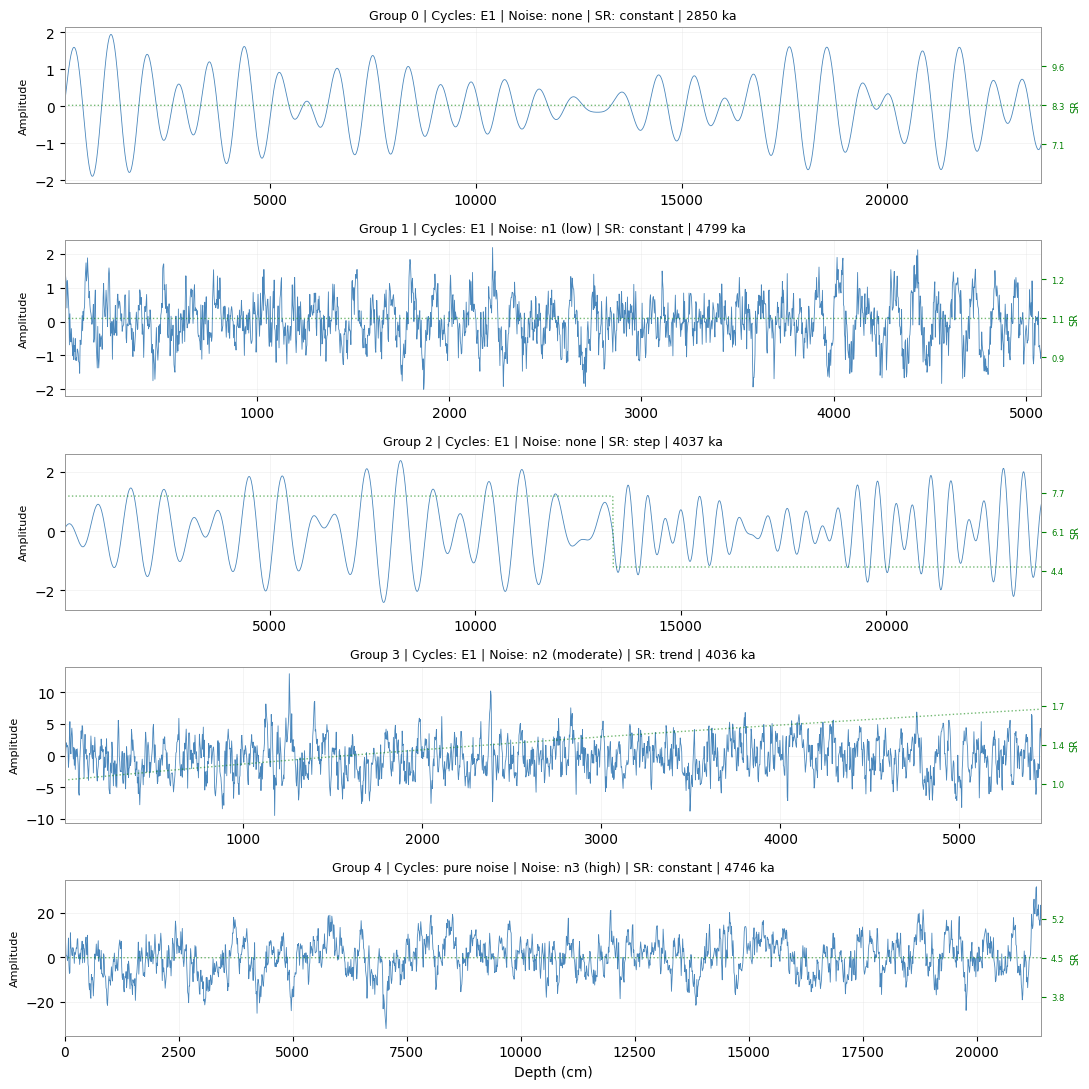

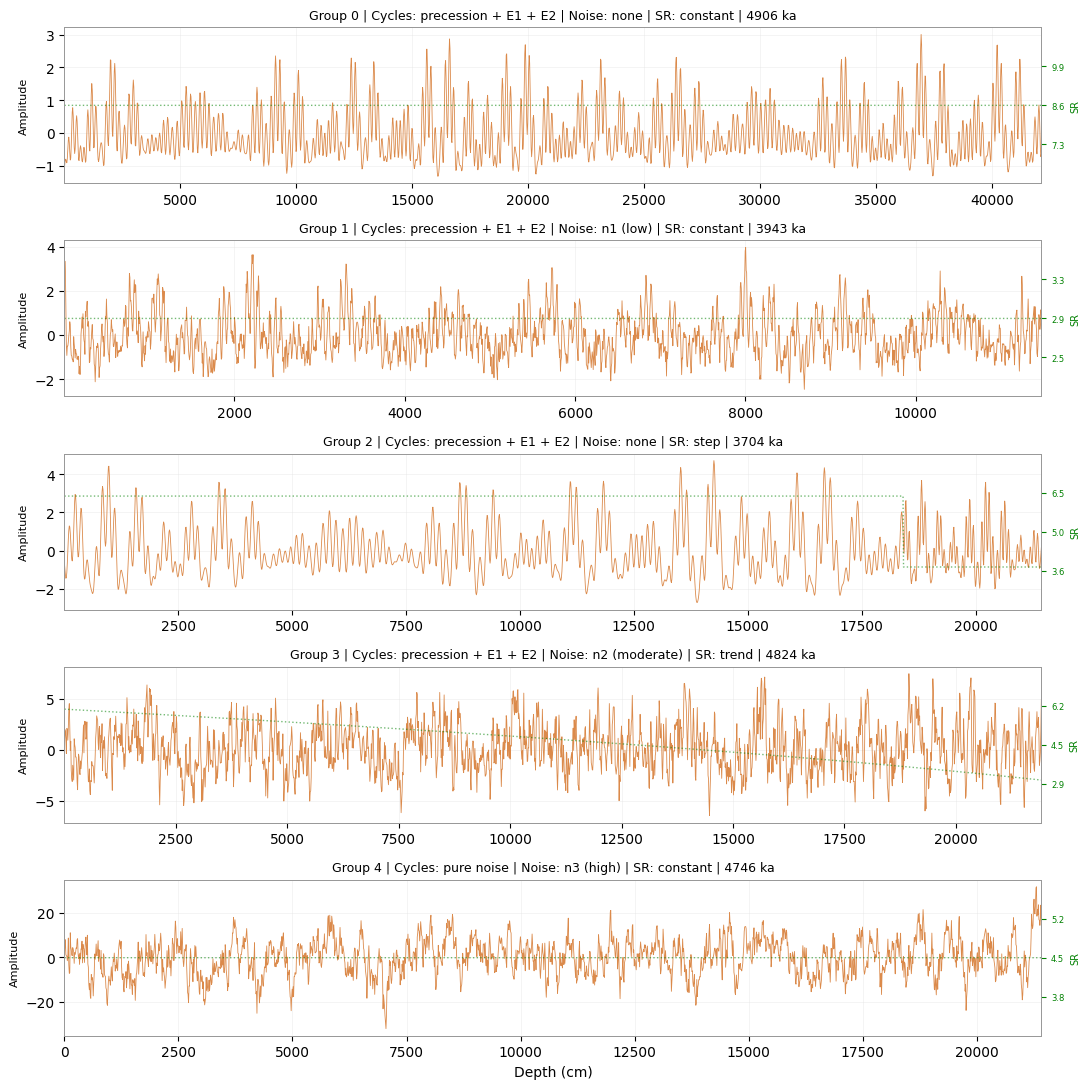

In [20]:

# Define noise labels and representative examples for each experimental group.
NOISE_LABELS = {None: "none", "n1": "n1 (low)", "n2": "n2 (moderate)", "n3": "n3 (high)"}

PANELS = [
    ("0", None, "constant"),
    ("1", "n1", "constant"),
    ("2", None, "step"),
    ("3", "n2", "trend"),
    ("4", "n3", "constant"),
]


def find_record(group, combo, noise_level, sr_mode):
    """Find the first record matching the specified experimental conditions."""
    for r in all_records:
        if (r["group"] == group and r["cycles_combo"] == combo
                and r["noise_level"] == noise_level and r["sr_mode"] == sr_mode):
            return r
    raise LookupError(f"no record for group {group}, combo {combo}, "
                      f"noise {noise_level}, sr {sr_mode}")


def sr_on_depth(record):
    """Reconstruct sedimentation rates along the depth axis."""
    params = record["sr_params"]
    if params["mode"] == "constant":
        return np.full_like(record["depth"], params["sr_start"])
    mask = (t_common >= record["t0"]) & (t_common < record["t0"] + record["length_kyr"])
    t = t_common[mask] - record["t0"]
    rate = sr_rate(t, params)
    return np.interp(record["depth"], np.cumsum(rate * np.gradient(t)), rate)


def plot_all_groups(combo, color, file_name):
    """Plot representative synthetic series and sedimentation rates for all groups."""
    records = [find_record(g, () if g == "4" else combo, nl, sr) for g, nl, sr in PANELS]

    fig, axs = plt.subplots(len(records), 1, figsize=(11, 2.2 * len(records)))
    for ax, r in zip(axs, records):
        ax.plot(r["depth"], r["signal"], lw=0.6, color=color)
        ax.set_xlim(r["depth"][0], r["depth"][-1])
        ax.set_ylabel("Amplitude", fontsize=8)

        rate = sr_on_depth(r)
        lo, hi = rate.min(), rate.max()
        margin = (hi - lo) * 0.6 if hi > lo else max(lo * 0.3, 0.3)

        ax2 = ax.twinx()
        ax2.grid(False)
        ax2.plot(r["depth"], rate, color="green", lw=1.0, alpha=0.55, ls=":")
        ax2.set_ylim(lo - margin, hi + margin)
        ax2.set_yticks(np.linspace(lo - margin, hi + margin, 5)[1:-1])
        ax2.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%.1f"))
        ax2.set_ylabel("SR", fontsize=7, color="green")
        ax2.tick_params(axis="y", labelsize=6, colors="green")

        cycles = " + ".join(r["cycles_combo"]) or "pure noise"
        ax.set_title(f'Group {r["group"]} | Cycles: {cycles} | '
                     f'Noise: {NOISE_LABELS[r["noise_level"]]} | '
                     f'SR: {r["sr_mode"]} | {r["length_kyr"]:.0f} ka', fontsize=9)

    axs[-1].set_xlabel("Depth (cm)")
    plt.tight_layout()
    for ext in ("pdf", "png"):
        plt.savefig(f"{file_name}.{ext}", bbox_inches="tight", dpi=300)
    plt.show()


# Generate figures for single-cycle and multi-cycle examples.
plot_all_groups(("E1",), "#4A87BC", "figure_single_cycle_all_groups")
plot_all_groups(("precession", "E1", "E2"), "#DB8A4B", "figure_combination_all_groups")
